# Contrast functions: float64 vs float32

Checks whether reading the MURaM intensities in single precision changes what `contrasts.contrast` produces (wavelength, I0, limb-darkening coefficients), and the facular contrast built from them.

Same inputs as the limb-darkening cell of `Actress_4376_continuum_SSD.ipynb`: 200G facula vs continuum SSD, 4376.5 to 4377.5 A, N = 50, power2.

How the precision is set: `contrast()` reads its file with `pd.read_csv(...).values`, which is always float64, and has no dtype option. For the float32 run, `pd.read_csv` is temporarily wrapped to pass `dtype=np.float32`, so the unmodified `contrst.contrast` runs on float32 data. What happens after the read is whatever NumPy does with float32 inputs (see the dtype trace cell). `scipy.optimize.curve_fit` always casts xdata/ydata to float64, so the fit itself is float64 in both runs. This tests **input precision**, not a fully float32 pipeline.

`contrast()` output goes to a temporary directory; this notebook writes no files.

Run from `actress_highres/actress/` (all paths are relative to it).

In [1]:
import os
import tempfile
from unittest import mock
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import actress.contrasts as contrst

In [2]:
# ----- inputs: same as the limb-darkening cell of Actress_4376_continuum_SSD.ipynb -----
fac_file = './inputs/limb_files/average_intensities_200G_driftcorrected.txt'
ssd_continuum_file = './inputs/limb_files/average_intensities_ssd_driftcorrected_continuum_4370_4384.txt'
source_files = {'fac': fac_file, 'phot': ssd_continuum_file}

# contrast() output from Actress_4376_continuum_SSD.ipynb, used only to check the float64 run reproduces it
existing_ld_files = {'fac': 'test_fac_200G_4376.txt', 'phot': 'test_phot_continuum_4376.txt'}

ld_law = 'power2'
wav_lower = 4.3765e-7   # m
wav_higher = 4.3775e-7  # m
N_ld = 50

precisions = {'float64': np.float64, 'float32': np.float32}
mu_columns = np.array([1, 0.9, 0.8, 0.7, 0.6, 0.5, 0.4, 0.3, 0.2])   # mu of the MURaM columns i10 ... i02

for path in list(source_files.values()) + list(existing_ld_files.values()):
    if not os.path.exists(path):
        raise FileNotFoundError(f"{path} not found; run Actress_4376_continuum_SSD.ipynb first")

contrst.validate_inputs(fac_file, ssd_continuum_file, wav_lower, wav_higher, graphs=False)

In [3]:
# ----- run contrst.contrast at both precisions -----
original_read_csv = pd.read_csv

def read_csv_as(dtype):
    """pd.read_csv with every column parsed as dtype; the MURaM files are all numeric."""
    def read_csv_with_dtype(*args, **kwargs):
        kwargs['dtype'] = dtype
        return original_read_csv(*args, **kwargs)
    return read_csv_with_dtype

def run_contrast(source_file, dtype, save_dir, name):
    """Unmodified contrst.contrast, with its input file read at the given dtype. Returns the saved table."""
    save_path = os.path.join(save_dir, f'{name}_{dtype.__name__}.txt')
    # contrst.pd is the pandas module itself, so the patch is undone as soon as the with block ends
    with mock.patch.object(contrst.pd, 'read_csv', read_csv_as(dtype)):
        contrst.contrast(source_file, wav_lower=wav_lower, wav_higher=wav_higher, N=N_ld, ld_law=ld_law, save=save_path, graphs=False)
    return np.loadtxt(save_path)

ld_fits = {}   # (name, precision) -> columns: wavelength (m), I0, a, b
with tempfile.TemporaryDirectory() as save_dir:
    for name, source_file in source_files.items():
        for precision, dtype in precisions.items():
            ld_fits[(name, precision)] = run_contrast(source_file, dtype, save_dir, name)

# The float64 run must be the same computation as the notebook that produced the simulation inputs.
for name, existing_file in existing_ld_files.items():
    if not np.array_equal(ld_fits[(name, 'float64')], np.loadtxt(existing_file)):
        raise ValueError(f"float64 contrast() output for {name} differs from {existing_file}")
    print(f"{name}: float64 run identical to {existing_file}")

for name in source_files:
    shape_64 = ld_fits[(name, 'float64')].shape
    shape_32 = ld_fits[(name, 'float32')].shape
    if shape_64 != shape_32:
        raise ValueError(f"{name}: float32 run kept {shape_32[0]} wavelengths, float64 run kept {shape_64[0]}")

Saved to /rds/general/user/dsy24/ephemeral/tmpi2d0cnas/fac_float64.txt
Saved to /rds/general/user/dsy24/ephemeral/tmpi2d0cnas/fac_float32.txt
Saved to /rds/general/user/dsy24/ephemeral/tmpi2d0cnas/phot_float64.txt
Saved to /rds/general/user/dsy24/ephemeral/tmpi2d0cnas/phot_float32.txt


fac: float64 run identical to test_fac_200G_4376.txt
phot: float64 run identical to test_phot_continuum_4376.txt


In [4]:
# ----- dtype trace: where float32 survives inside contrast() -----
# Same helpers and the same delta_freq expression as contrasts.contrast, on one float32 row,
# to show which steps stay float32 and which NumPy promotes to float64.
raw_32 = original_read_csv(fac_file, sep=r'\s+', comment='#', dtype=np.float32).values
wavelength_m_32 = list(contrst.wav_nm_to_m(raw_32[:, 0]))
intensity_32 = contrst.intensity_si(raw_32)
i = len(wavelength_m_32) // 2
delta_freq_32 = ((-(3e8/(wavelength_m_32[i+1]))+(3e8/(wavelength_m_32[i])))/2) + ((-(3e8/(wavelength_m_32[i]))+(3e8/(wavelength_m_32[i-1])))/2)

print(f"raw file values          : {raw_32.dtype}")
print(f"wavelength_m (list items): {type(wavelength_m_32[i]).__name__}")
print(f"intensity_si             : {intensity_32[0].dtype}")
print(f"delta_freq               : {type(delta_freq_32).__name__}   (3e8 / float32 scalar promotes to float64, but from float32-rounded wavelengths)")
print(f"I = intensity * delta_freq: {type(intensity_32[0][i] * delta_freq_32).__name__}")
print("curve_fit                : casts xdata / ydata to float64")

raw file values          : float32
wavelength_m (list items): float32
intensity_si             : float32
delta_freq               : float64   (3e8 / float32 scalar promotes to float64, but from float32-rounded wavelengths)
I = intensity * delta_freq: float64
curve_fit                : casts xdata / ydata to float64


       max |dwav| (A)  max |I0_32/I0_64 - 1|   max |da|   max |db|
fac          3.80e-04               2.32e-02   1.35e-05   1.06e-06
phot         3.80e-04               2.32e-02   1.66e-09   1.92e-08


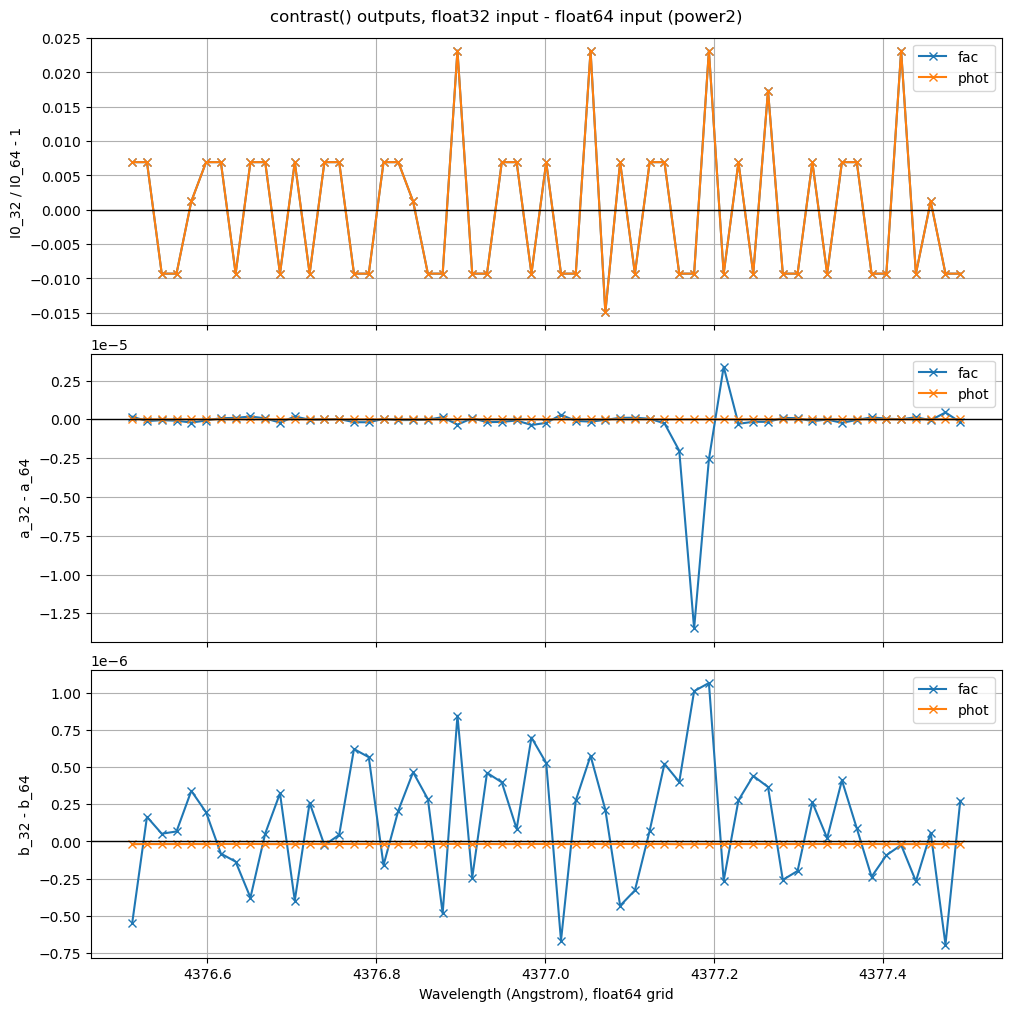

In [5]:
# ----- fitted outputs: float32 vs float64 -----
column_names = ['wavelength', 'I0', 'a', 'b']

print(f"{'':5s} {'max |dwav| (A)':>15s} {'max |I0_32/I0_64 - 1|':>22s} {'max |da|':>10s} {'max |db|':>10s}")
for name in source_files:
    fit_64 = ld_fits[(name, 'float64')]
    fit_32 = ld_fits[(name, 'float32')]
    wav_diff = np.max(np.abs(fit_32[:, 0] - fit_64[:, 0])) * 1e10   # A
    I0_rel_diff = np.max(np.abs(fit_32[:, 1] / fit_64[:, 1] - 1))
    a_diff = np.max(np.abs(fit_32[:, 2] - fit_64[:, 2]))
    b_diff = np.max(np.abs(fit_32[:, 3] - fit_64[:, 3]))
    print(f"{name:5s} {wav_diff:15.2e} {I0_rel_diff:22.2e} {a_diff:10.2e} {b_diff:10.2e}")

fit_wavelengths = ld_fits[('phot', 'float64')][:, 0] * 1e10   # A

fig, axes = plt.subplots(3, 1, figsize=(10, 10), sharex=True, constrained_layout=True)
for name in source_files:
    fit_64 = ld_fits[(name, 'float64')]
    fit_32 = ld_fits[(name, 'float32')]
    axes[0].plot(fit_wavelengths, fit_32[:, 1] / fit_64[:, 1] - 1, 'x-', label=name)
    axes[1].plot(fit_wavelengths, fit_32[:, 2] - fit_64[:, 2], 'x-', label=name)
    axes[2].plot(fit_wavelengths, fit_32[:, 3] - fit_64[:, 3], 'x-', label=name)
axes[0].set_ylabel('I0_32 / I0_64 - 1')
axes[1].set_ylabel('a_32 - a_64')
axes[2].set_ylabel('b_32 - b_64')
axes[2].set_xlabel('Wavelength (Angstrom), float64 grid')
for ax in axes:
    ax.axhline(0, color='k', linewidth=1)
    ax.legend()
    ax.grid(True)
fig.suptitle(f'contrast() outputs, float32 input - float64 input ({ld_law})')
plt.show()

fac   max |I0 ratio / delta_freq ratio - 1| = 1.20e-07
phot  max |I0 ratio / delta_freq ratio - 1| = 2.45e-08


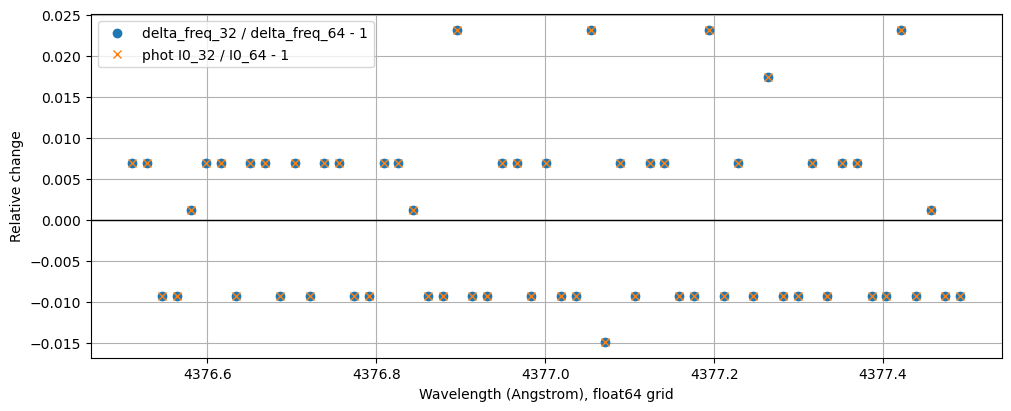

In [6]:
# ----- is the I0 change the bin width? -----
# I0 = I(mu=1) in SI x delta_freq, with delta_freq from differences of neighbouring 3e8/wavelength.
# Neighbouring wavelengths differ by ~0.0087 A out of ~4377 A (2e-6 relative), close to float32's
# ~6e-8 relative spacing, so rounding the wavelengths to float32 changes delta_freq by up to a few percent.
# If that is the whole effect, I0_32/I0_64 equals delta_freq_32/delta_freq_64 at every wavelength.
def delta_freq_at_fits(dtype, fit):
    """delta_freq (Hz) at the fitted rows, by the formula in contrasts.contrast (c = 3e8 there)."""
    raw = original_read_csv(ssd_continuum_file, sep=r'\s+', comment='#', dtype=dtype).values
    raw_wavelengths = contrst.wav_nm_to_m(raw[:, 0])   # m
    delta_freqs = []
    for fit_wavelength in fit[:, 0]:
        row = int(np.argmin(np.abs(raw_wavelengths - fit_wavelength)))
        if raw_wavelengths[row] != fit_wavelength.astype(dtype):
            raise ValueError(f"Fitted wavelength {fit_wavelength} is not a row of {ssd_continuum_file} at {dtype.__name__}")
        # same expression as contrasts.contrast, on Python-list elements as there
        wav_m = list(raw_wavelengths)
        delta_freq = ((-(3e8/(wav_m[row+1]))+(3e8/(wav_m[row])))/2) + ((-(3e8/(wav_m[row]))+(3e8/(wav_m[row-1])))/2)
        delta_freqs.append(delta_freq)
    return np.array(delta_freqs, dtype=np.float64)

delta_freq_64 = delta_freq_at_fits(np.float64, ld_fits[('phot', 'float64')])
delta_freq_32 = delta_freq_at_fits(np.float32, ld_fits[('phot', 'float32')])
delta_freq_ratio = delta_freq_32 / delta_freq_64

for name in source_files:
    I0_ratio = ld_fits[(name, 'float32')][:, 1] / ld_fits[(name, 'float64')][:, 1]
    residual = I0_ratio / delta_freq_ratio - 1
    print(f"{name:5s} max |I0 ratio / delta_freq ratio - 1| = {np.max(np.abs(residual)):.2e}")

fig, ax = plt.subplots(figsize=(10, 4), constrained_layout=True)
ax.plot(fit_wavelengths, delta_freq_ratio - 1, 'o', label='delta_freq_32 / delta_freq_64 - 1')
ax.plot(fit_wavelengths, ld_fits[('phot', 'float32')][:, 1] / ld_fits[('phot', 'float64')][:, 1] - 1, 'x', label='phot I0_32 / I0_64 - 1')
ax.axhline(0, color='k', linewidth=1)
ax.set_xlabel('Wavelength (Angstrom), float64 grid')
ax.set_ylabel('Relative change')
ax.legend()
ax.grid(True)
plt.show()

  mu  max |contrast|  max |c_32 - c_64|
 1.0       9.034e-01           1.01e-07
 0.6       8.847e-01           6.59e-08
 0.2       8.527e-01           1.19e-07


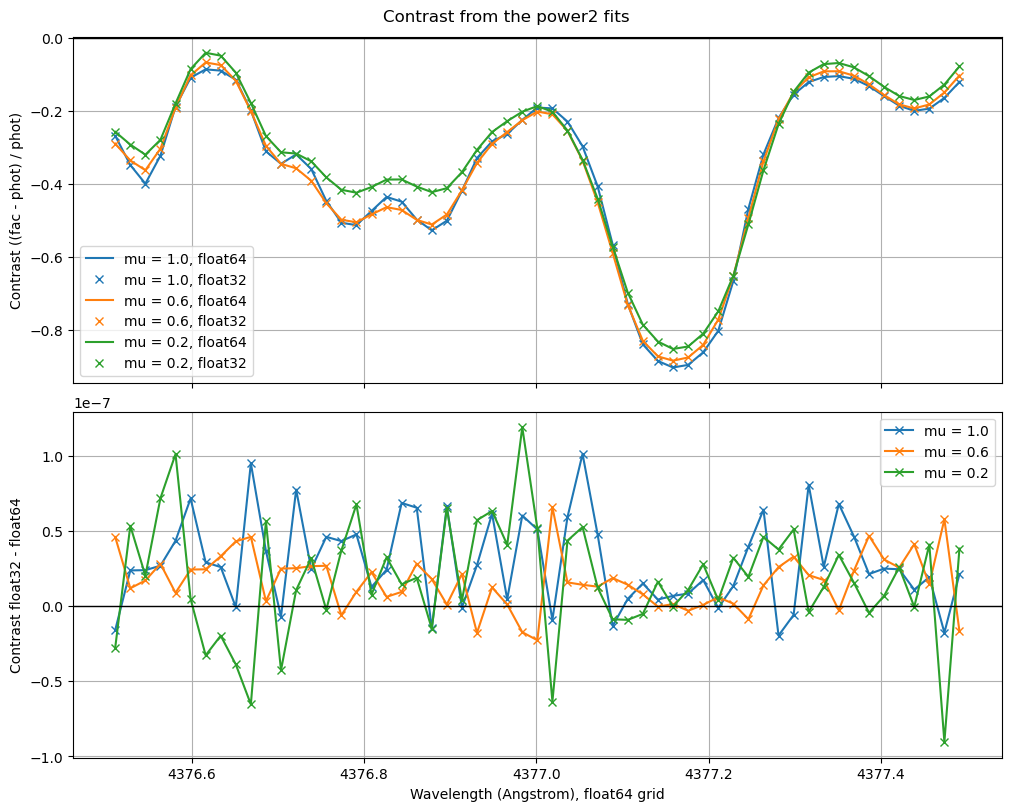

In [7]:
# ----- facular contrast (fac - phot) / phot at several mu, both precisions -----
# fac and phot share the wavelength grid (validate_inputs), so the same delta_freq multiplies both
# and should cancel in the contrast even where I0 itself moves.
def fitted_intensity(fit, mu):
    """I(mu) at every fitted wavelength, through the same contrst.ld the fit used (power2 / quadratic only)."""
    x = contrst.costheta_to_ster(mu)
    return contrst.ld(x, fit[:, 2], fit[:, 3], fit[:, 1], ld_law)

def fitted_contrast(precision, mu):
    I_fac = fitted_intensity(ld_fits[('fac', precision)], mu)
    I_phot = fitted_intensity(ld_fits[('phot', precision)], mu)
    return (I_fac - I_phot) / I_phot

mu_plot = [1.0, 0.6, 0.2]

fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True, constrained_layout=True)
print(f"{'mu':>4s} {'max |contrast|':>15s} {'max |c_32 - c_64|':>18s}")
for mu in mu_plot:
    contrast_64 = fitted_contrast('float64', mu)
    contrast_32 = fitted_contrast('float32', mu)
    if not (np.all(np.isfinite(contrast_64)) and np.all(np.isfinite(contrast_32))):
        raise ValueError(f"Non-finite fitted contrast at mu = {mu}")
    print(f"{mu:4.1f} {np.max(np.abs(contrast_64)):15.3e} {np.max(np.abs(contrast_32 - contrast_64)):18.2e}")
    line, = axes[0].plot(fit_wavelengths, contrast_64, '-', label=f'mu = {mu}, float64')
    axes[0].plot(fit_wavelengths, contrast_32, 'x', color=line.get_color(), label=f'mu = {mu}, float32')
    axes[1].plot(fit_wavelengths, contrast_32 - contrast_64, 'x-', color=line.get_color(), label=f'mu = {mu}')
axes[0].set_ylabel('Contrast ((fac - phot) / phot)')
axes[1].set_ylabel('Contrast float32 - float64')
axes[1].set_xlabel('Wavelength (Angstrom), float64 grid')
for ax in axes:
    ax.axhline(0, color='k', linewidth=1)
    ax.legend()
    ax.grid(True)
fig.suptitle(f'Contrast from the {ld_law} fits')
plt.show()

In [8]:
# ----- same contrast straight from the MURaM columns (no fit, no delta_freq) -----
# Isolates the effect of float32 on the intensities themselves from anything the fit does.
raw_fac = {precision: original_read_csv(fac_file, sep=r'\s+', comment='#', dtype=dtype).values for precision, dtype in precisions.items()}
raw_phot = {precision: original_read_csv(ssd_continuum_file, sep=r'\s+', comment='#', dtype=dtype).values for precision, dtype in precisions.items()}

in_window = (raw_phot['float64'][:, 0] >= wav_lower * 1e9) & (raw_phot['float64'][:, 0] <= wav_higher * 1e9)   # file column is nm

print(f"{'mu':>4s} {'max |c_32 - c_64|':>18s}")
for column, mu in enumerate(mu_columns, start=1):
    contrast_by_precision = {}
    for precision in precisions:
        fac_column = raw_fac[precision][in_window, column]
        phot_column = raw_phot[precision][in_window, column]
        contrast_by_precision[precision] = (fac_column - phot_column) / phot_column
    difference = contrast_by_precision['float32'].astype(np.float64) - contrast_by_precision['float64']
    print(f"{mu:4.1f} {np.max(np.abs(difference)):18.2e}")

  mu  max |c_32 - c_64|
 1.0           5.60e-08
 0.9           4.25e-08
 0.8           6.19e-08
 0.7           6.72e-08
 0.6           7.01e-08
 0.5           8.26e-08
 0.4           5.78e-08
 0.3           5.38e-08
 0.2           5.30e-08


phot SI rounding error at mu = 1 (same at every wavelength): -2.448e-08
c_32 - c_64 at mu = 1: 46 of 57 points > 0, mean 2.949e-08
predicted from rounding alone: mean 2.949e-08, max |actual - predicted| = 2.77e-16
common scale from float32(1e-7): 1.169e-08 (cancels in the contrast)
  phot term -(1 + c) (err_phot - common): mean 2.313e-08
  fac term   (1 + c) (err_fac - common) : mean 6.354e-09

  mu  phot SI error  points > 0  points < 0  mean c_32 - c_64
 1.0     -2.448e-08          91          23         2.731e-08
 0.9      3.238e-08          42          72        -1.225e-08
 0.8      4.387e-08          34          80        -1.978e-08
 0.7     -2.134e-08          85          29         2.503e-08
 0.6     -5.032e-08          96          18         3.682e-08
 0.5     -6.940e-08         102          12         5.264e-08
 0.4     -1.950e-09          67          47         9.270e-09
 0.3      3.259e-09          68          46         4.923e-09
 0.2      1.460e-08          63          51 

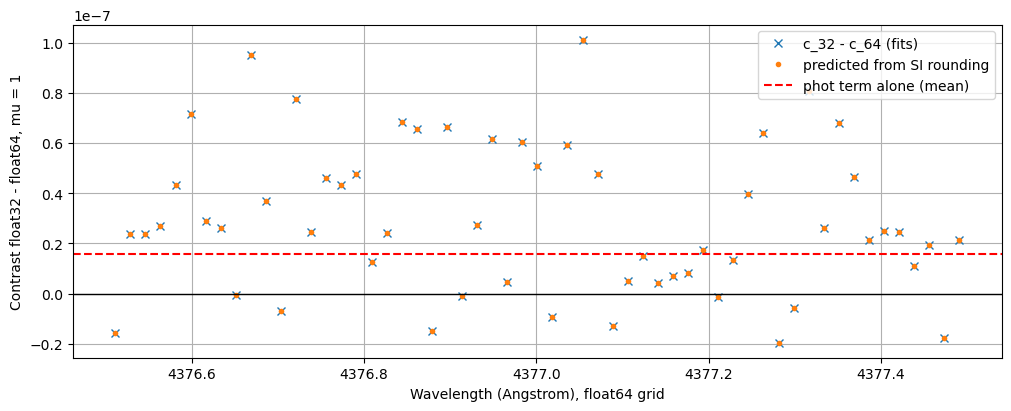

In [9]:
# ----- why the float32 contrast at mu = 1.0 sits systematically above float64 -----
# The continuum SSD file holds one intensity per mu (flat in wavelength), so its float32 rounding error is the
# same at every wavelength and shifts every contrast point the same way; the facula varies with wavelength, so
# its rounding errors only scatter. contrasts.cgs_to_si multiplies the float32 array by 1e-7 then by 100**2,
# rounding again at each step, so the error is taken on the SI values contrast() actually uses.
# At mu = 1 contrst.ld returns I0 exactly (no fitted coefficients enter) and delta_freq is common to fac and
# phot, so the expected difference is
#   c_32 - c_64 = (1 + c_64) * (err_fac - err_phot) / (1 + err_phot),  err = SI_32 / SI_64 - 1.
for column, mu in enumerate(mu_columns, start=1):
    n_unique = np.unique(raw_phot['float64'][:, column]).size
    if n_unique != 1:
        raise ValueError(f"{ssd_continuum_file} is not flat in wavelength at mu = {mu} ({n_unique} distinct values)")

# rows of the raw files that contrast() kept
raw_wavelengths_m = contrst.wav_nm_to_m(raw_phot['float64'][:, 0])   # m
fit_rows = []
for fit_wavelength in ld_fits[('phot', 'float64')][:, 0]:
    fit_rows.append(int(np.argmin(np.abs(raw_wavelengths_m - fit_wavelength))))
fit_rows = np.array(fit_rows)

def si_rounding_error(raw, rows, column):
    """Relative error of the float32 SI intensity against the float64 one, as contrast() computes it."""
    si_32 = contrst.cgs_to_si(raw['float32'][rows, column]).astype(np.float64)
    si_64 = contrst.cgs_to_si(raw['float64'][rows, column])
    return si_32 / si_64 - 1

err_fac = si_rounding_error(raw_fac, fit_rows, 1)
err_phot = si_rounding_error(raw_phot, fit_rows, 1)
contrast_64_mu1 = fitted_contrast('float64', 1.0)
difference_mu1 = fitted_contrast('float32', 1.0) - contrast_64_mu1
predicted_mu1 = (1 + contrast_64_mu1) * (err_fac - err_phot) / (1 + err_phot)

print(f"phot SI rounding error at mu = 1 (same at every wavelength): {err_phot[0]:.3e}")
print(f"c_32 - c_64 at mu = 1: {np.sum(difference_mu1 > 0)} of {len(difference_mu1)} points > 0, mean {difference_mu1.mean():.3e}")
print(f"predicted from rounding alone: mean {predicted_mu1.mean():.3e}, max |actual - predicted| = {np.max(np.abs(difference_mu1 - predicted_mu1)):.2e}")
# float32(1e-7) is itself inexact, so cgs_to_si scales fac and phot by the same factor; it cancels in the
# contrast, so remove it before splitting the difference into a phot and a fac term.
common_scale_error = float(np.float32(1e-7)) / 1e-7 - 1
print(f"common scale from float32(1e-7): {common_scale_error:.3e} (cancels in the contrast)")
print(f"  phot term -(1 + c) (err_phot - common): mean {np.mean(-(1 + contrast_64_mu1) * (err_phot - common_scale_error)):.3e}")
print(f"  fac term   (1 + c) (err_fac - common) : mean {np.mean((1 + contrast_64_mu1) * (err_fac - common_scale_error)):.3e}")

# Direction at every mu, straight from the MURaM columns: the sign of the shift should follow -err_phot.
print(f"\n{'mu':>4s} {'phot SI error':>14s} {'points > 0':>11s} {'points < 0':>11s} {'mean c_32 - c_64':>17s}")
window_rows = np.where(in_window)[0]
for column, mu in enumerate(mu_columns, start=1):
    err_phot_mu = si_rounding_error(raw_phot, window_rows, column)[0]
    contrast_by_precision = {}
    for precision in precisions:
        fac_si = contrst.cgs_to_si(raw_fac[precision][window_rows, column])
        phot_si = contrst.cgs_to_si(raw_phot[precision][window_rows, column])
        contrast_by_precision[precision] = (fac_si - phot_si) / phot_si
    difference = contrast_by_precision['float32'].astype(np.float64) - contrast_by_precision['float64']
    print(f"{mu:4.1f} {err_phot_mu:14.3e} {np.sum(difference > 0):11d} {np.sum(difference < 0):11d} {difference.mean():17.3e}")

fig, ax = plt.subplots(figsize=(10, 4), constrained_layout=True)
ax.plot(fit_wavelengths, difference_mu1, 'x', label='c_32 - c_64 (fits)')
ax.plot(fit_wavelengths, predicted_mu1, '.', label='predicted from SI rounding')
ax.axhline(np.mean(-(1 + contrast_64_mu1) * err_phot), color='r', linestyle='--', label='phot term alone (mean)')
ax.axhline(0, color='k', linewidth=1)
ax.set_xlabel('Wavelength (Angstrom), float64 grid')
ax.set_ylabel('Contrast float32 - float64, mu = 1')
ax.legend()
ax.grid(True)
plt.show()